# 06 — Backtest multi-pata con costos y walk-forward

**Dueño:** Juan Manuel Espinosa (JME) · **Revisor:** Gonzalo Cano (GC) · **Guía:** `docs/instrucciones/06_backtest.md`

**Objetivo.** Simular la estrategia día a día con contabilidad exacta por pata, comisión por pata, préstamo sobre los
cortos y evaluación walk-forward (entrenamiento → prueba → validación) con los parámetros congelados desde train.

> Este notebook solo **muestra**: la lógica vive en `backtest/` (motor, costos, walk-forward) y `strategy/sizing.py`;
> `python main.py` corre lo mismo y escribe `equity_curve.parquet`, `trades.csv` y `rebalance_comparison.csv`.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from backtest.costs import BORROW_RATE_ANNUAL, COMMISSION, TRADING_DAYS
from backtest.engine import DEFAULT_PARAMS, run_backtest
from backtest.walk_forward import run_walk_forward, split_summary
from data.split import load_split_dates
from main import ARTIFACTS, FIGURES

pd.set_option("display.width", 160)
prices = pd.read_parquet(ARTIFACTS / "prices.parquet").drop(columns="split")
signals = pd.read_parquet(ARTIFACTS / "signals.parquet")
equity = pd.read_parquet(ARTIFACTS / "equity_curve.parquet")
trades = pd.read_csv(ARTIFACTS / "trades.csv", parse_dates=["entry_date", "exit_date"])
rebalance = pd.read_csv(ARTIFACTS / "rebalance_comparison.csv")
strategy = json.loads((ARTIFACTS / "params.json").read_text())["strategy"]
dates = load_split_dates(ARTIFACTS / "split_dates.json")
print(f"Señales: {signals.index[0].date()} → {signals.index[-1].date()} ({len(signals)} días, después de ambos burn-in)")

Señales: 2013-04-08 → 2026-10-30 (3414 días, después de ambos burn-in)


## 1. Cómo funciona el motor

Cada día t, con precios de cierre P_t:

1. **Valuación:** P&L bruto_t = Σ_i q_i (P_{i,t} − P_{i,t−1}) con las acciones que se traían de t − 1.
2. **Préstamo:** (0.25 % / 252) × nocional de las patas cortas mantenidas de t − 1 a t.
3. **Ejecución al cierre de t de la señal decidida al cierre de t − 1** (evita el look-ahead de operar al mismo
   cierre que generó la señal). Acciones objetivo con el sizing de clase:
   N_i = 0.8 · V_t · |β̂_i| / Σ|β̂_j|, q_i = d · sgn(β̂_i) · N_i / P_i, con V_t el capital actual.
4. **Comisión** de 0.125 % sobre lo operado **en cada pata** (entrada, salida y rebalanceos).
5. **Identidad contable:** equity_t = cash_t + Σ_i q_i P_{i,t} y ΔV_t = bruto − comisión − préstamo.

Mientras la posición sigue abierta se **rebalancea** hacia el objetivo (cambian β̂_t y V_t): cada día con
`rebalance_band = 0`, o solo las patas que se alejan más de la banda.

In [2]:
print("Parámetros del motor:", DEFAULT_PARAMS)
print(f"Comisión {COMMISSION:.3%} por pata; préstamo {BORROW_RATE_ANNUAL:.2%} anual, base {TRADING_DAYS} días")
print("Regla θ congelada desde train (parte 05):",
      {k: strategy[k] for k in ("z_entry", "z_exit", "z_stop", "max_holding")})

Parámetros del motor: {'initial_capital': 1000000.0, 'position_fraction': 0.8, 'commission': 0.00125, 'borrow_rate': 0.0025, 'trading_days': 252, 'execution_lag': 1, 'rebalance_band': 0.0}
Comisión 0.125% por pata; préstamo 0.25% anual, base 252 días
Regla θ congelada desde train (parte 05): {'z_entry': 1.0, 'z_exit': 0.5, 'z_stop': 3.0, 'max_holding': 51}


### Caso de juguete calculado a mano (el mismo de `tests/test_accounting.py`)

Dos patas con β = (1, −1). La señal +1 del cierre del día 0 se ejecuta el día 1 (400,000 largo en A y 400,000 corto
en B, comisión 0.125 % × 800,000 = 1,000); la señal 0 del día 1 cierra el día 2.

In [3]:
index = pd.bdate_range("2024-01-01", periods=4)
toy_prices = pd.DataFrame({"A": [100.0, 110.0, 120.0, 120.0], "B": [50.0, 50.0, 40.0, 40.0]}, index=index)
toy_signals = pd.DataFrame({"signal": [1, 0, 0, 0], "beta_A": 1.0, "beta_B": -1.0}, index=index)
toy = run_backtest(toy_prices, toy_signals)
toy.equity[["shares_A", "shares_B", "cash", "value_A", "value_B", "equity", "gross_pnl", "commission", "borrow",
            "net_pnl"]].round(2)

,shares_A,shares_B,cash,value_A,value_B,equity,gross_pnl,commission,borrow,net_pnl
2024-01-01,0.00,0.0,1000000.00,0.0,0.0,1000000.00,0.00,0.00,0.00,0.00
2024-01-02,3636.36,-8000.0,999000.00,400000.0,-400000.0,999000.00,0.00,1000.00,0.00,-1000.00
2024-01-03,0.00,0.0,1114415.01,0.0,0.0,1114415.01,116363.64,945.45,3.17,115415.01
2024-01-04,0.00,0.0,1114415.01,0.0,0.0,1114415.01,0.00,0.00,0.00,0.00


## 2. Walk-forward con θ congelado

Cada partición se simula por separado desde el primer día con señal, arranca con $1,000,000 y cierra sus posiciones al
final. Prueba y validación usan exactamente la regla, los filtros y los costos calibrados en train.

In [4]:
results = run_walk_forward(prices.loc[signals.index], signals, dates)
summary = pd.DataFrame({name: split_summary(result) for name, result in results.items()}).T
summary.style.format({"net_return": "{:+.2%}", "sharpe_net": "{:.2f}", "max_drawdown": "{:.2%}", "gross_pnl": "{:,.0f}",
                      "commission": "{:,.0f}", "borrow": "{:,.0f}", "net_pnl": "{:,.0f}", "cost_share_of_gross": "{:.0%}",
                      "traded_notional": "{:,.0f}", "win_rate": "{:.0%}", "exposure": "{:.0%}"})

,net_return,sharpe_net,max_drawdown,gross_pnl,commission,borrow,net_pnl,cost_share_of_gross,traded_notional,n_trades,win_rate,n_rebalances,exposure
train,+23.89%,0.77,-3.87%,"327,422","85,806","2,671","238,946",27%,"68,644,638",35.000000,80%,615.000000,34%
test,+2.37%,0.33,-2.17%,"51,690","27,088",922,"23,679",54%,"21,670,714",12.000000,75%,218.000000,31%
validation,+2.86%,0.39,-2.62%,"49,921","20,632",689,"28,600",43%,"16,505,694",9.000000,67%,177.000000,25%


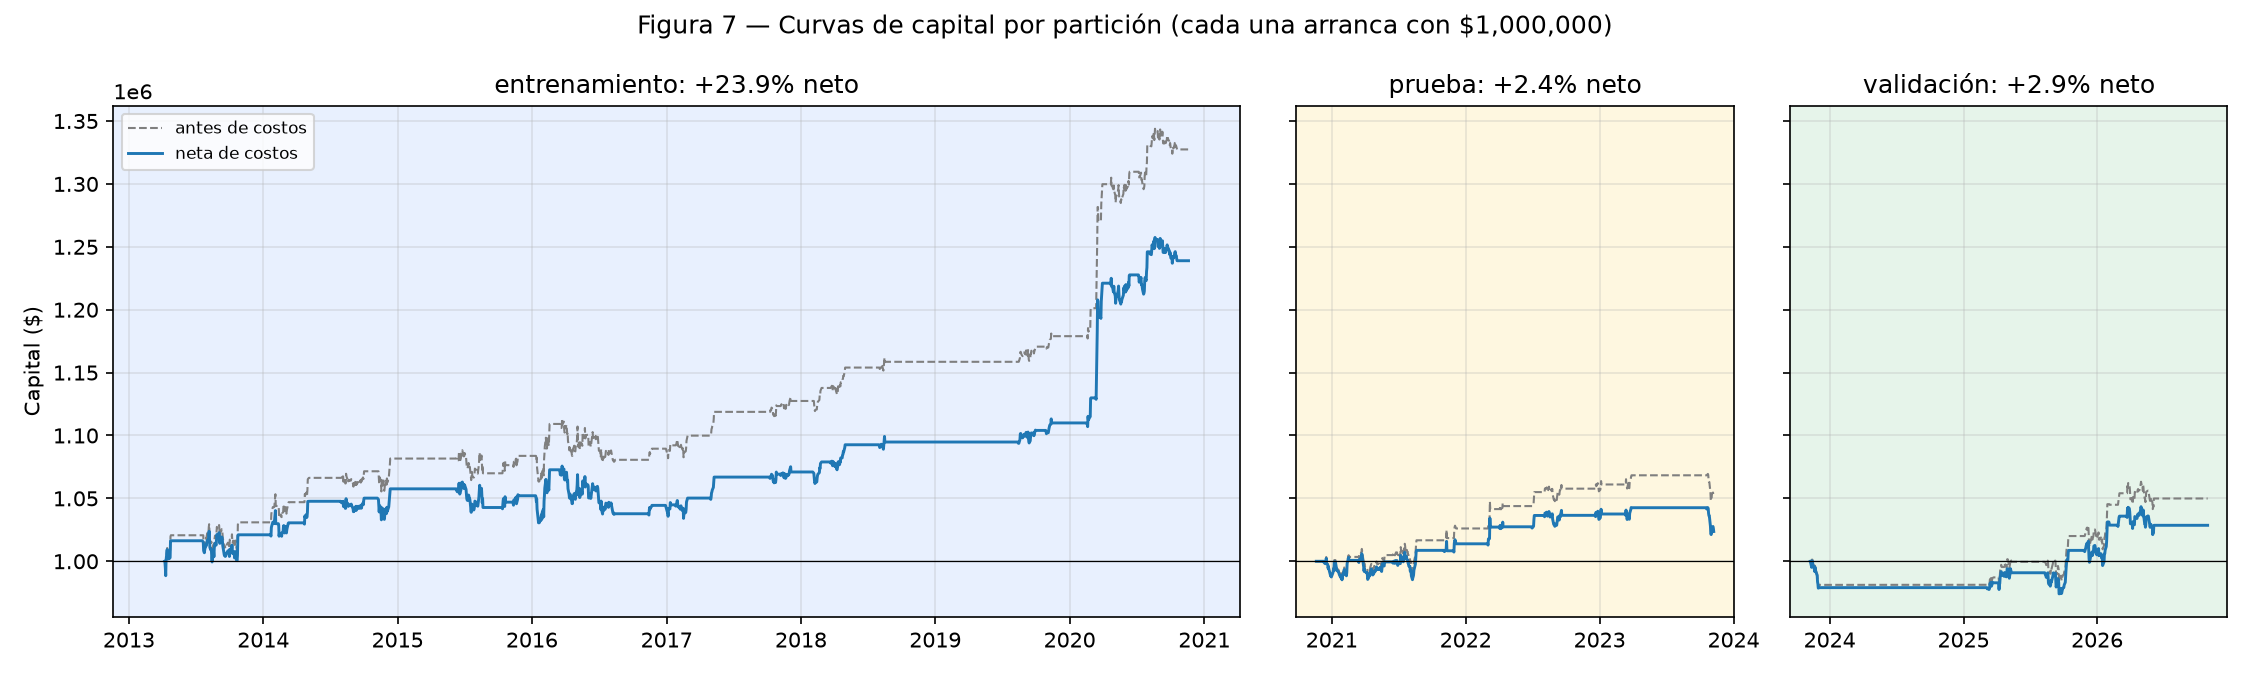

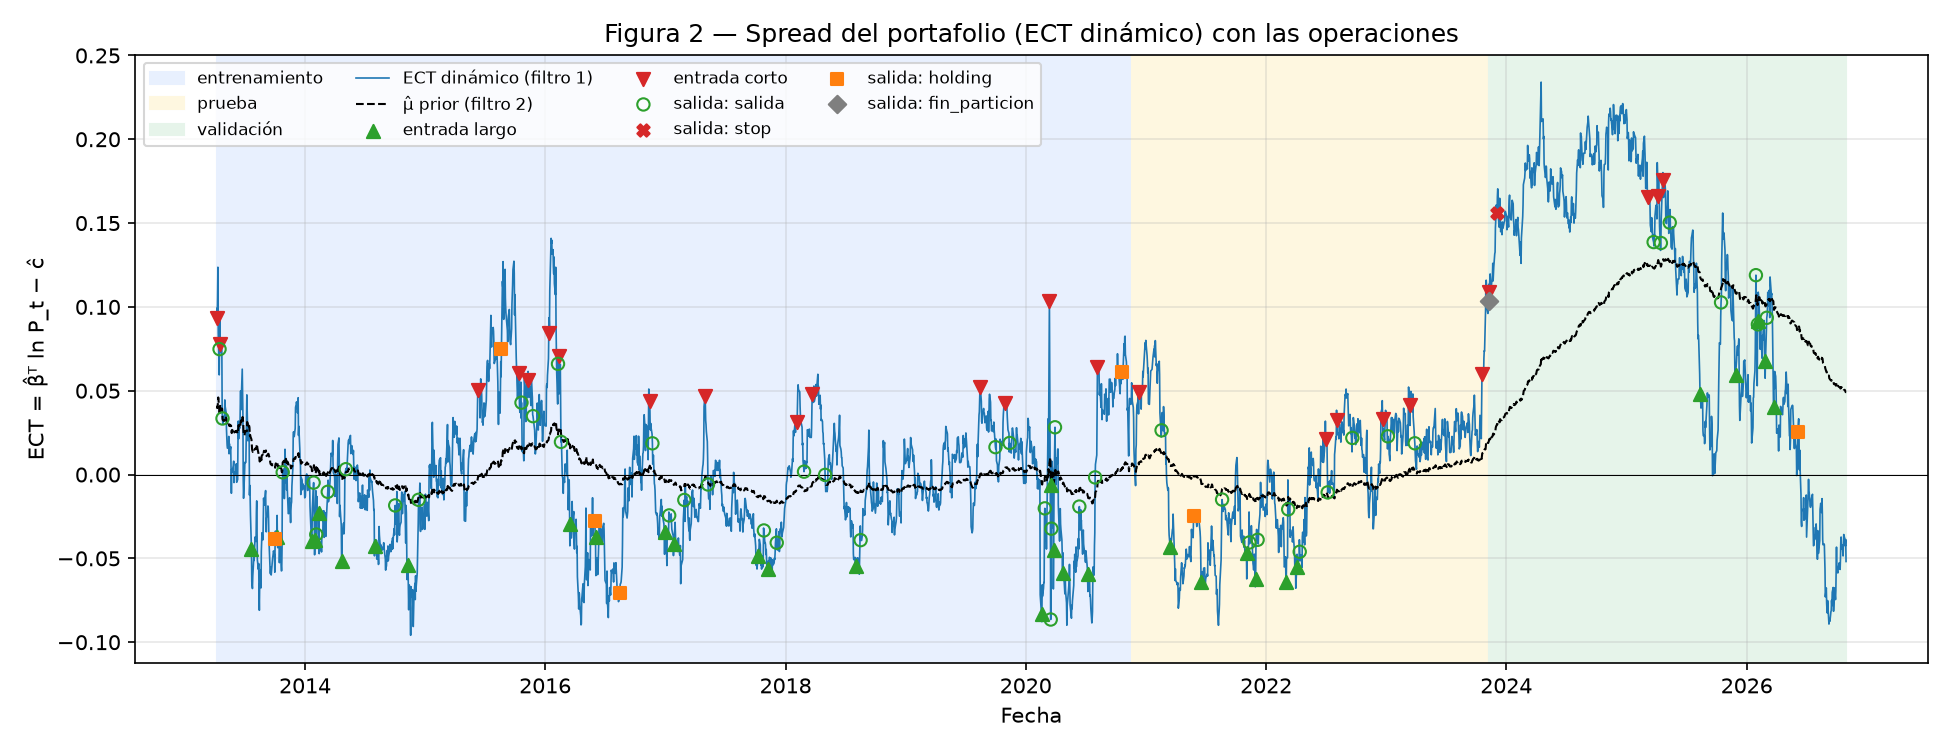

In [5]:
display(Image(filename=str(FIGURES / "fig07_curvas_capital.png")))
display(Image(filename=str(FIGURES / "fig02_spread_senales.png")))

**Lectura.**
- **Entrenamiento:** +23.9 % neto en 7.5 años, Sharpe neto 0.77, drawdown máximo −3.9 %. Es dentro de muestra: θ se
  eligió aquí.
- **Prueba y validación:** +2.4 % y +2.9 % netos, Sharpe 0.33 y 0.39. La estrategia sigue ganando fuera de muestra,
  pero mucho menos: la degradación es la esperada al pasar de datos de ajuste a datos nuevos.
- **Validación:** el stop del 2023-12-04 desarma la dirección corta y la regla de rearme deja a la estrategia
  **fuera hasta marzo de 2025** (el ECT se quedó lejos de su media, figura 2). Esa pausa de 15 meses es la que evita
  seguir perdiendo en el tramo donde la relación de train se rompió; después gana 6 de sus 8 operaciones.

## 3. Bitácora de operaciones

In [6]:
by_reason = trades.groupby(["split", "exit_reason"], sort=False)["net_pnl"].agg(operaciones="count", neto_total="sum",
                                                                          neto_promedio="mean")
by_reason.style.format({"neto_total": "{:,.0f}", "neto_promedio": "{:,.0f}"})

In [7]:
trades.sort_values("net_pnl").head(5)[["split", "entry_date", "exit_date", "direction", "days", "gross_pnl",
                                         "commission", "borrow", "net_pnl", "exit_reason"]].round({"gross_pnl": 0, "commission": 0, "borrow": 0, "net_pnl": 0})

,split,entry_date,exit_date,direction,days,gross_pnl,commission,borrow,net_pnl,exit_reason
16,train,2016-06-02,2016-08-15,1,51,-19860.0,2942.0,172.0,-22974.0,holding
47,validation,2023-11-10,2023-12-04,-1,15,-18755.0,2120.0,71.0,-20946.0,stop
46,test,2023-10-20,2023-11-08,-1,13,-16665.0,2179.0,64.0,-18907.0,fin_particion
10,train,2015-06-10,2015-08-21,-1,51,-11712.0,2872.0,255.0,-14839.0,holding
30,train,2020-03-18,2020-03-19,1,1,-11092.0,2439.0,4.0,-13535.0,salida


**Cómo pierde dinero la estrategia.** Las salidas por **salida** (reversión a la media) son las que ganan; las
pérdidas vienen de posiciones que **no revierten**: salidas por holding máximo (51 días sin regresar), el stop de
validación y el cierre forzado al final de prueba. Es exactamente el riesgo de la sesión 14: una relación que deja de
revertir mientras el modelo insiste en que la reversión es inminente.

## 4. Atribución de costos: bruto = neto + comisiones + préstamo

In [8]:
attribution = equity.groupby("split", sort=False)[["gross_pnl", "commission", "borrow", "net_pnl"]].sum()
attribution["bruto − (neto + costos)"] = attribution["gross_pnl"] - (attribution["net_pnl"] + attribution["commission"]
                                                                    + attribution["borrow"])
attribution.round(2)

,gross_pnl,commission,borrow,net_pnl,bruto − (neto + costos)
split,,,,,
train,327422.46,85805.80,2670.63,238946.03,0.0
test,51689.81,27088.39,922.13,23679.28,-0.0
validation,49921.17,20632.12,688.76,28600.29,0.0


Las comisiones son 27 % del P&L bruto en train y más de 40 % fuera de muestra: con 4 patas, cada operación
completa paga 8 comisiones más las de los rebalanceos. El préstamo es pequeño (0.25 % anual sobre la mitad corta).

## 5. Rebalanceo diario vs banda de no-rebalanceo

La política evaluada es el rebalanceo **diario** (con la que se eligió θ en train). La banda b solo opera una pata
cuando su nocional se aleja más de b de su objetivo.

In [9]:
cols = ["rebalance_band", "split", "net_return", "sharpe_net", "max_drawdown", "commission", "cost_share_of_gross",
        "n_rebalances", "traded_notional"]
rebalance[cols].style.format({"net_return": "{:+.2%}", "sharpe_net": "{:.2f}", "max_drawdown": "{:.2%}",
                              "commission": "{:,.0f}", "cost_share_of_gross": "{:.0%}", "traded_notional": "{:,.0f}"})

,rebalance_band,split,net_return,sharpe_net,max_drawdown,commission,cost_share_of_gross,n_rebalances,traded_notional
0,0.000000,train,+23.89%,0.77,-3.87%,"85,806",27%,615,"68,644,638"
1,0.000000,test,+2.37%,0.33,-2.17%,"27,088",54%,218,"21,670,714"
2,0.000000,validation,+2.86%,0.39,-2.62%,"20,632",43%,177,"16,505,694"
3,0.050000,train,+24.73%,0.79,-3.77%,"80,025",25%,175,"64,019,647"
4,0.050000,test,+2.29%,0.32,-2.24%,"25,296",53%,43,"20,237,019"
5,0.050000,validation,+3.38%,0.45,-2.46%,"19,165",37%,57,"15,331,830"
6,0.100000,train,+24.31%,0.78,-3.69%,"77,666",25%,54,"62,132,788"
7,0.100000,test,+2.99%,0.41,-2.22%,"24,973",46%,14,"19,978,726"
8,0.100000,validation,+3.55%,0.46,-2.63%,"18,977",36%,23,"15,181,349"
9,0.200000,train,+27.86%,0.86,-3.31%,"77,313",22%,10,"61,850,482"


**Lectura.** Rebalancear a diario cuesta: con banda de 20 % los rebalanceos bajan de 615 a 10 en train y las
comisiones bajan ≈ 10 %. Lo importante es que **la comparación se puede hacer solo con train**, y en train la banda
de 20 % también es la mejor (Sharpe 0.86 contra 0.77). Se reporta como escenario; cambiar la política oficial después
de ver prueba y validación sería ajustar a esos datos, así que la evaluación oficial se queda con el rebalanceo
diario.

## Resumen de resultados (parte 06)

| Resultado | Entrenamiento | Prueba | Validación |
|---|---|---|---|
| Rendimiento neto | +23.9 % | +2.4 % | +2.9 % |
| Sharpe neto | 0.77 | 0.33 | 0.39 |
| Drawdown máximo | −3.9 % | −2.2 % | −2.6 % |
| Operaciones | 35 | 12 | 9 |
| Costos / P&L bruto | 27 % | 54 % | 43 % |

- **Contabilidad:** identidad equity = cash + Σ patas en cada día y atribución bruto = neto + costos exactas
  (`test_accounting`, prueba 3).
- **Sin look-ahead en la ejecución:** la señal del cierre de t se opera al cierre de t + 1.
- **Hallazgo:** la estrategia gana fuera de muestra pero se degrada; las pérdidas vienen de spreads que no revierten
  (holding, stop) y la regla de rearme la saca del mercado durante el quiebre (diciembre de 2023 a marzo de 2025).
- **Rebalanceo:** la banda de 20 % reduce costos y también gana en train; se reporta como escenario.